# Exemple 12 : runs using climate variants, used for INNOVACC modeling training, april 2026

The aim of this notebook is to provide a full working example of simulations performed using variant entry datasets for INNOVACC modeling training, april 2026.

## Imports

In [ ]:
import numpy as np
import datetime
from matplotlib import pyplot as plt
from tqdm import tqdm as tqdm
import xarray as xr
from sarra_py import *
from sarra_py import ModelParameters, SimulationConfig, load_model_parameters, run_simulation as run_sarra_simulation, select_daily_window, validate_input_dataset
import geopandas as gpd
from joblib import Parallel, delayed
import xarray as xr
import numpy as np
import datetime
from tqdm import tqdm
import copy

## Defining simulation dates

We begin by defining two key parameters for the simulation: `date_start` and `duration`.

- **`date_start`**: The start date of the simulation. This defines the first day for which data will be loaded and marks the beginning of daily water balance computations. It is recommended to set this date approximately one month before the expected sowing date. This allows the water balance to stabilize before the effective sowing date, which is critical since the emergence phase is triggered by a specific level of soil moisture.

- **`duration`**: The length of the simulation in days. This parameter specifies the number of daily cycles after `date_start` during which computations will run. It determines the time range covered by the simulation and sets the size of the time dimension in the computation arrays. Only the days within the interval `[date_start, date_start + duration]` will be used for calculations.


## 1. Loading data

### 1.1. define climate data paths

In [2]:
# defining the path to the NetCDF datasets
rainfall_data_path = "../data/exemple_data/exemple_12/rainfall/01-tamsatDaily.v3.1-20230101-20231231-20260318_11.43_16.36_6.8_13.19.nc"
tmax_data_path = "../data/exemple_data/exemple_12/tmax/*.nc"
tmin_data_path = "../data/exemple_data/exemple_12/tmin/*.nc"
solar_radiation_flux_data_path = "../data/exemple_data/exemple_12/solar_radiation_flux/*.nc"

### 1.2. load climate data

In [3]:
# We load the netCDF file for rainfall in order to get the size of the computational grid.
# We transpose the axes as the provided file was incorrectly formatted.
rainfall_data = xr.open_dataset(rainfall_data_path)
grid_width, grid_height = len(rainfall_data["lat"]), len(rainfall_data["lon"])
print("The grid is {} pixels wide by {} pixels high.".format(grid_width, grid_height))

# initialize empty xarray dataset
base_data = xr.Dataset()

# Loading the rainfall variable
rainfall_data = rainfall_data["rfe_filled"].transpose("time", "lat", "lon")
# We put this data into the base_data dataarray, and apply the standard attributes
base_data["rain"] = rainfall_data
base_data["rain"].attrs = {"units": "mm", "long_name": "rainfall"}
# free up memory
del rainfall_data

# set names and CRS for base_data
base_data = base_data.rename({'lat': 'y', 'lon': 'x'})
base_data = base_data.rio.set_spatial_dims(x_dim="x", y_dim="y")
base_data = base_data.rio.write_crs("EPSG:4326")

# Loading the weather variables
# tmax
tmax_data = xr.open_mfdataset(tmax_data_path, combine="by_coords", engine="netcdf4")
tmax_data = tmax_data["Temperature_Air_2m_Max_24h"].transpose("time", "lat", "lon")
tmax_data = tmax_data - 273.15  # convert from Kelvin to Celsius
# Rename + CRS + align on rainfall grid
tmax_data = tmax_data.rename({'lat': 'y', 'lon': 'x'})
tmax_data = tmax_data.rio.write_crs("EPSG:4326")
tmax_data = tmax_data.rio.set_spatial_dims(x_dim="x", y_dim="y")
tmax_data = tmax_data.rio.reproject_match(base_data)

# tmin
tmin_data = xr.open_mfdataset(tmin_data_path, combine="by_coords", engine="netcdf4")
tmin_data = tmin_data["Temperature_Air_2m_Min_24h"].transpose("time", "lat", "lon")
tmin_data = tmin_data - 273.15  # convert from Kelvin to Celsius
# Rename + CRS + align on rainfall grid
tmin_data = tmin_data.rename({'lat': 'y', 'lon': 'x'})
tmin_data = tmin_data.rio.write_crs("EPSG:4326")
tmin_data = tmin_data.rio.set_spatial_dims(x_dim="x", y_dim="y")
tmin_data = tmin_data.rio.reproject_match(base_data)

# calculating the mean temperature, and putting it into the base_data dataarray
tmean_data = (tmax_data + tmin_data) / 2
base_data["tpMoy"] = tmean_data

# Loading solar radiation flux data NetCDF, also applying transposition, and subsetting to the dates we need
solar_radiation_flux_data = xr.open_mfdataset(solar_radiation_flux_data_path, combine="by_coords", engine="netcdf4")
solar_radiation_flux_data = solar_radiation_flux_data["Solar_Radiation_Flux"].transpose("time", "lat", "lon")
solar_radiation_flux_data = solar_radiation_flux_data / 1_000_000  # convert from W/m² to MJ/m²/day
# Rename + CRS + align on rainfall grid
solar_radiation_flux_data = solar_radiation_flux_data.rename({'lat': 'y', 'lon': 'x'})
solar_radiation_flux_data = solar_radiation_flux_data.rio.write_crs("EPSG:4326")
solar_radiation_flux_data = solar_radiation_flux_data.rio.set_spatial_dims(x_dim="x", y_dim="y")
solar_radiation_flux_data = solar_radiation_flux_data.rio.reproject_match(base_data)
# putting it into the base_data dataarray
base_data["rg"] = solar_radiation_flux_data

# calculate ET0 using the Hargreaves-Samani method
# ET0 = 0.0023 * (Tmax - Tmin) ** 0.5 * (Tmax + Tmin) / 2 * (Solar_Radiation_Flux)
base_data["ET0"] = 0.0023 * (tmax_data - tmin_data) ** 0.5 * tmean_data * (base_data["rg"])

# Proceed with loading soil data and calculating day length
base_data = load_iSDA_soil_data_alternate(base_data, grid_width, grid_height)

# # compute day length raster
# base_data = calc_day_length_raster_fast(base_data, date_start, duration)

The grid is 172 pixels wide by 132 pixels high.


### 1.3. define alternate climate scenarios

In [4]:
# define alternative climate scenarios by applying perturbations to the weather variables
# - pluviométrie faible : -20% pluie
low_rain_data = base_data.copy()
low_rain_data["rain"] = low_rain_data["rain"] * 0.8

# - début tardif de la saison des pluies : 0 pluie en juin
late_onset_data = base_data.copy()
late_onset_data["rain"] = late_onset_data["rain"].where(late_onset_data["rain"].time.dt.month != 6, 0)

# - vague de chaleur en floraison avec augmentation des température sà la date de floraison : +4°C mois d'aout
heat_wave_data = base_data.copy()
heat_wave_tmax_data = tmax_data.where(tmax_data.time.dt.month != 8, tmax_data + 4)
heat_wave_data["tpMoy"] = (heat_wave_tmax_data + tmin_data) / 2
heat_wave_data["ET0"] = 0.0023 * (heat_wave_tmax_data - tmin_data) ** 0.5 * heat_wave_data["tpMoy"] * (heat_wave_data["rg"] / 0.408)

In [5]:
# free up memory
del tmax_data
del heat_wave_tmax_data
del tmin_data
del solar_radiation_flux_data

## 2. Defining run parameters

In [ ]:
# parameter file names (files are located in the ../data/parameters/ folder)
file_paramVariete = "variety_exemple_2.yaml"
file_paramITK = "itk_exemple_2.yaml"
file_paramTypeSol = "USA_iowa_V42.yaml"

# populate param variables with variety, cropping system and soil parameters
parameters = load_model_parameters(
    f"../data/params/variety/{file_paramVariete}",
    f"../data/params/itk/{file_paramITK}",
    f"../data/params/soil/{file_paramTypeSol}",
)
paramVariete = dict(parameters.variety)
paramITK = dict(parameters.management)
paramTypeSol = dict(parameters.soil)

# date début de simulation (default = 01/04)
year = 2023
month_start = 4
day_start = 1

# duration of the simulation (in days)
duration = (datetime.date(year, 12, 31) - datetime.date(year, month_start, day_start)).days + 1

# date début de semis (default = 01/05)
month_sowing = 5
day_sowing = 1

# on force les paramètres optimisés
paramVariete["SDJRPR"] = 489.0
paramVariete["SDJLevee"] = 250.0
paramVariete["SDJBVP"] = 636.0
paramVariete["slaMin"] = 285.0
paramVariete["slaMax"] = 363.2
paramVariete["SDJMatu1"] = 848.0
paramVariete["SDJMatu2"] = 334.0
paramVariete["KRdtPotA"] = 0.9

## 3. Run

Each climate scenario is restricted to the 2023 growing season and run through the validated API. The model creates day length and irrigation inputs when needed.


In [ ]:
scenarios = {
    "Baseline": base_data,
    "Low rainfall (-20%)": low_rain_data,
    "Late onset (no rain in June)": late_onset_data,
    "Heat wave (+4C in August)": heat_wave_data,
}

def run_scenario(name, scenario_data):
    scenario_paramVariete = copy.deepcopy(paramVariete)
    scenario_paramITK = copy.deepcopy(paramITK)
    scenario_paramITK["DateSemis"] = datetime.date(year, month_sowing, day_sowing)
    date_start = datetime.date(year, month_start, day_start)
    
    inputs = select_daily_window(scenario_data, date_start, duration)
    sim_data = run_sarra_simulation(
        inputs,
        ModelParameters(scenario_paramVariete, scenario_paramITK, paramTypeSol),
        SimulationConfig(date_start, duration),
    )

    return name, sim_data

final_yields = {}
water_stress = {}


for name, scenario_data in scenarios.items():
    _, result = run_scenario(name, scenario_data)
    final_yields[name] = result["rdt"].isel(time=-1)
    water_stress[name] = result["cstr"].mean(dim="time")
    


### 3.2. Plot results

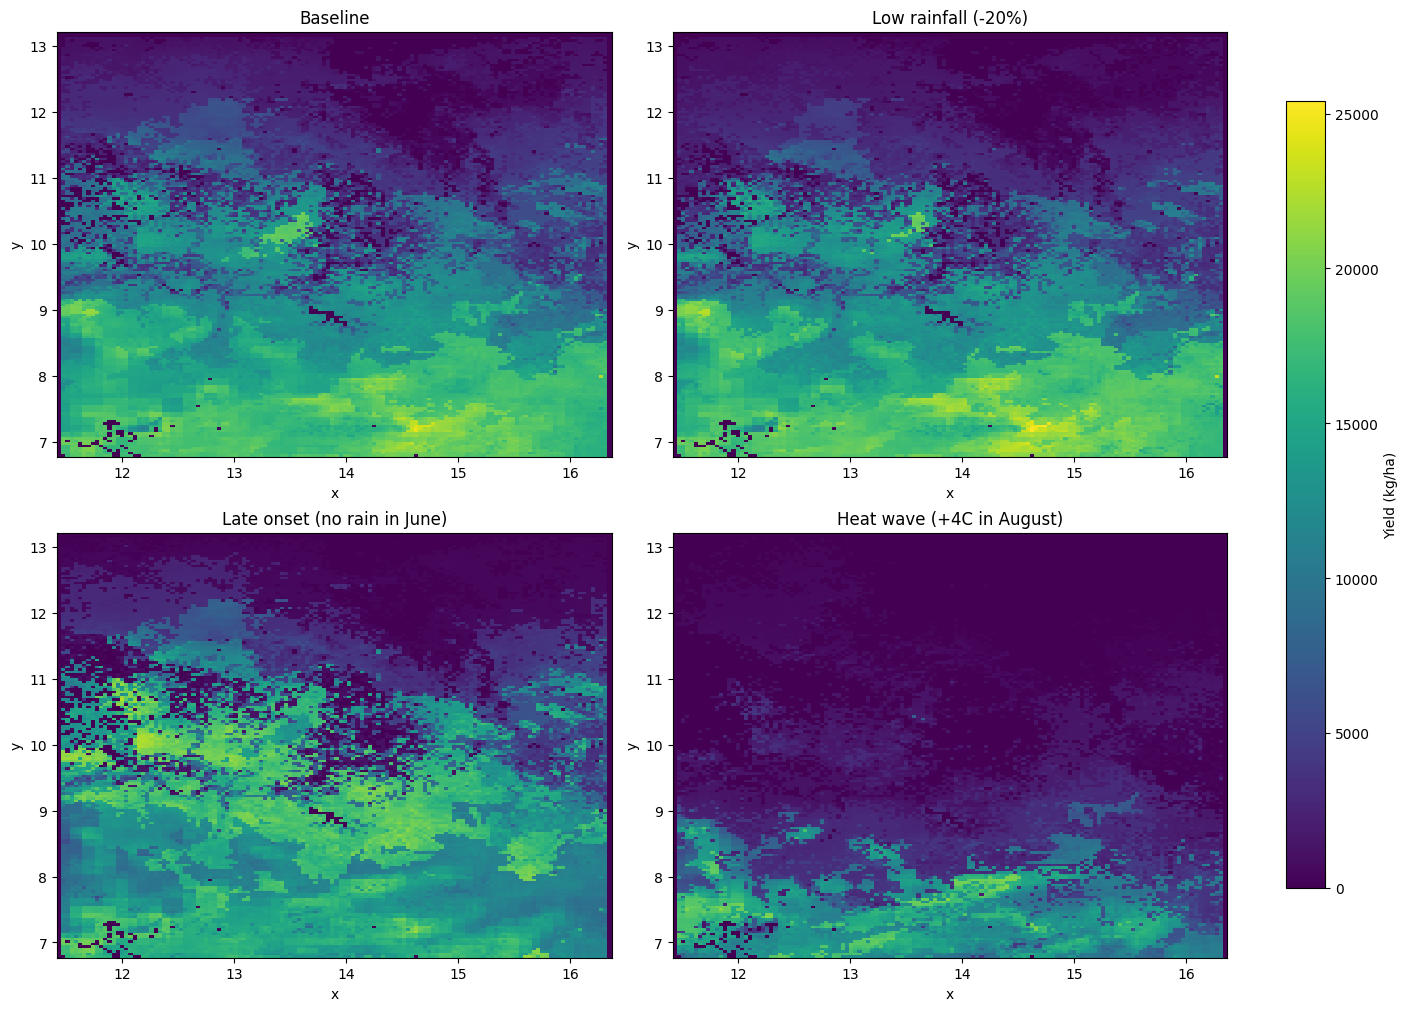

In [8]:
vmin = min(float(rdt.min()) for rdt in final_yields.values())
vmax = max(float(rdt.max()) for rdt in final_yields.values())

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
axes = axes.flatten()

mappable = None
for ax, (name, rdt) in zip(axes, final_yields.items()):
    mappable = rdt.plot(ax=ax, cmap="viridis", vmin=vmin, vmax=vmax, add_colorbar=False)
    ax.set_title(name)

fig.colorbar(mappable, ax=axes.tolist(), shrink=0.85, label="Yield (kg/ha)")
plt.show()

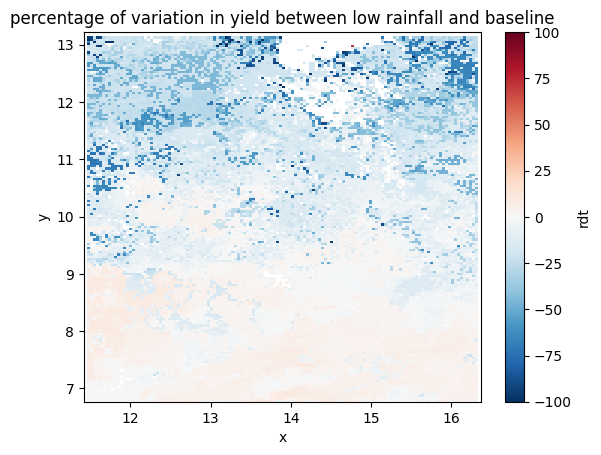

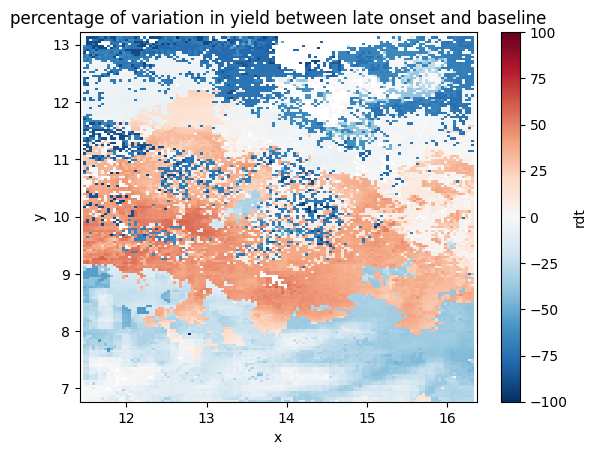

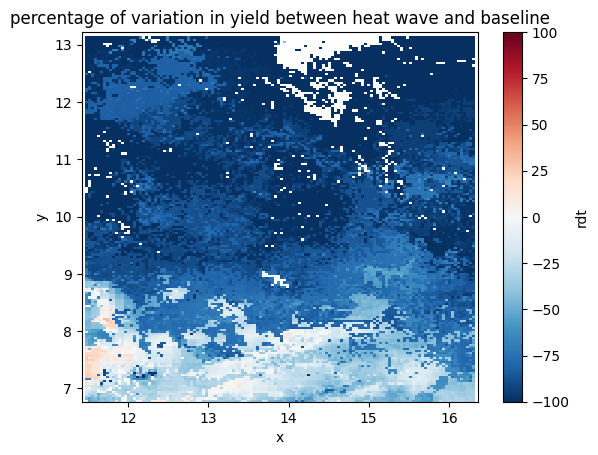

In [9]:
# compute a percentage of variation in comparison with baseline and plot it
(((final_yields["Low rainfall (-20%)"]-final_yields["Baseline"])/final_yields["Baseline"])*100.0).plot()
plt.title("percentage of variation in yield between low rainfall and baseline")
plt.show()

# compute a percentage of variation in comparison with baseline and plot it
(((final_yields["Late onset (no rain in June)"]-final_yields["Baseline"])/final_yields["Baseline"])*100.0).plot()
plt.title("percentage of variation in yield between late onset and baseline")
plt.show()

# compute a percentage of variation in comparison with baseline and plot it
(((final_yields["Heat wave (+4C in August)"]-final_yields["Baseline"])/final_yields["Baseline"])*100.0).plot()
plt.title("percentage of variation in yield between heat wave and baseline")
plt.show()

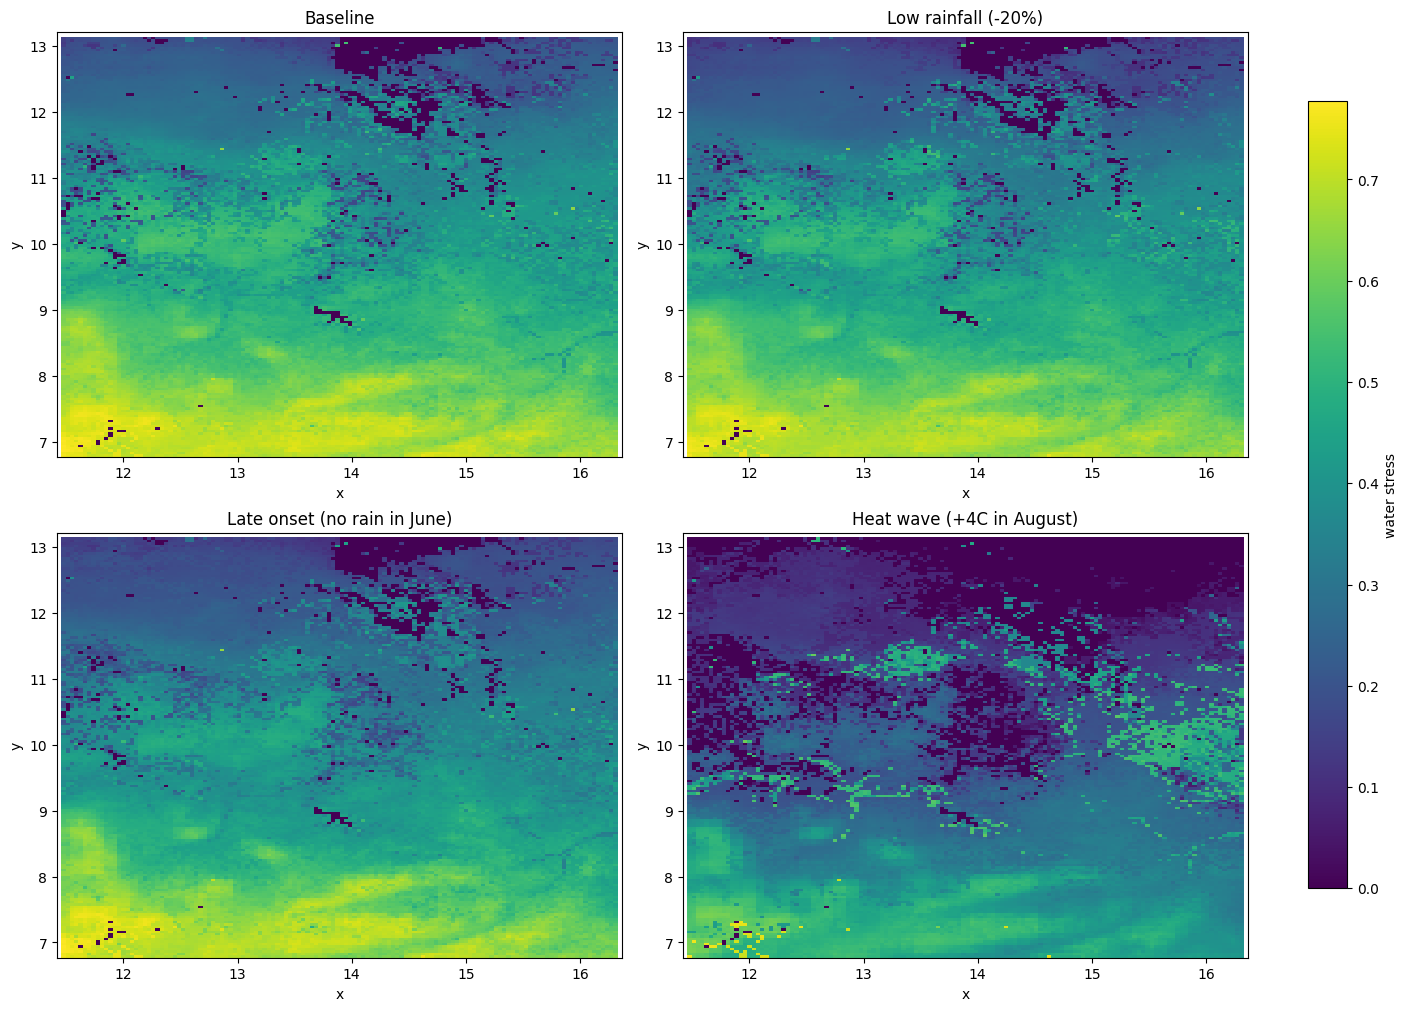

In [12]:
vmin = min(float(rdt.min()) for rdt in water_stress.values())
vmax = max(float(rdt.max()) for rdt in water_stress.values())

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
axes = axes.flatten()

mappable = None
for ax, (name, rdt) in zip(axes, water_stress.items()):
    mappable = rdt.plot(ax=ax, cmap="viridis", vmin=vmin, vmax=vmax, add_colorbar=False)
    ax.set_title(name)

fig.colorbar(mappable, ax=axes.tolist(), shrink=0.85, label="water stress")
plt.show()

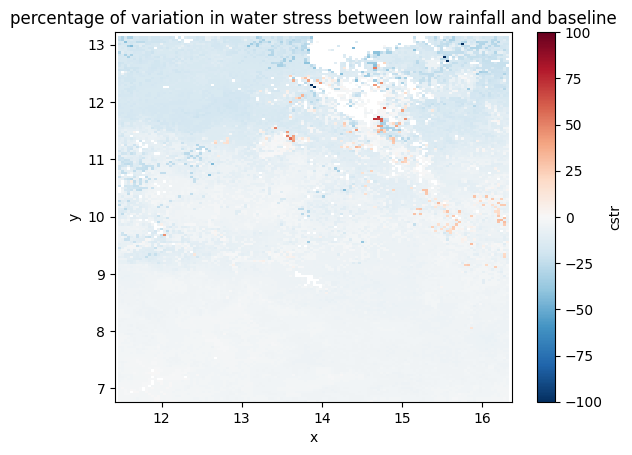

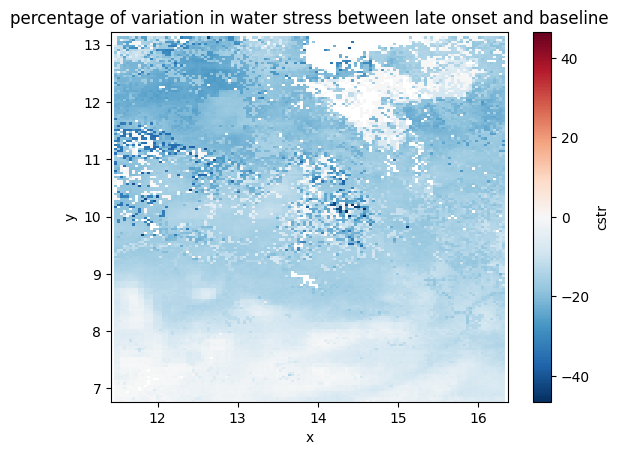

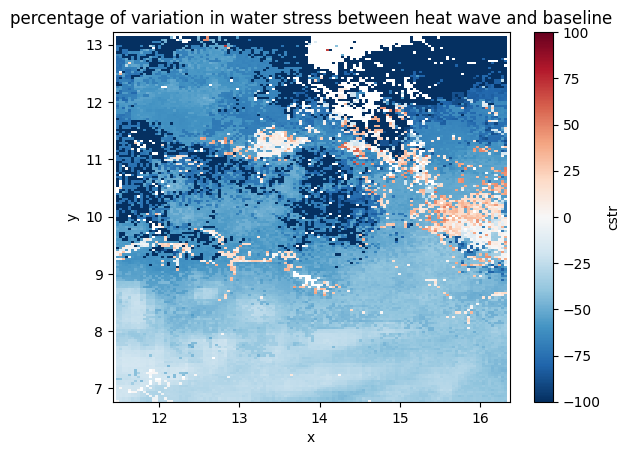

In [14]:
# compute a percentage of variation in comparison with baseline and plot it
(((water_stress["Low rainfall (-20%)"]-water_stress["Baseline"])/water_stress["Baseline"])*100.0).plot()
plt.title("percentage of variation in water stress between low rainfall and baseline")
plt.show()

# compute a percentage of variation in comparison with baseline and plot it
(((water_stress["Late onset (no rain in June)"]-water_stress["Baseline"])/water_stress["Baseline"])*100.0).plot()
plt.title("percentage of variation in water stress between late onset and baseline")
plt.show()

# compute a percentage of variation in comparison with baseline and plot it
(((water_stress["Heat wave (+4C in August)"]-water_stress["Baseline"])/water_stress["Baseline"])*100.0).plot()
plt.title("percentage of variation in water stress between heat wave and baseline")
plt.show()